# Fully synthetic multi-line PN dataset for NGC 253

Each sample contains:

- a synthetic, spatially structured nebular background;
- one unresolved PN;
- one complete PN spectrum selected from the model CSV;
- a Moffat PSF;
- a PN-centre heatmap.

The model CSV is already normalized to Hα = 1. For each PN, the complete model row is scaled to a selected observed [O III] 5007 magnitude \(m_{5007}\).

The network input shape will be:

```text
(number of samples, number of emission lines, 64, 64)
```

The target shape will be:

```text
(number of samples, 1, 64, 64)
```
## 2. Configuration

## 3. Load the PN models

The CSV is normalized to Hα = 1.

## 4. Scale one model row to an absolute \$m_{5007}\$

The observed integrated [O III] 5007 flux is

$$
F_{5007} = 10^{-0.4(m_{5007}+13.74)}.
$$

The full Hα-normalized model row is multiplied by one common scale factor, so all physical line ratios are preserved.

## 5. Spatial functions
Same normalized Moffat PSF is used in every emission line map.

## 6. Create a synthetic multi-line background

The Hα map defines the main morphology. It contains:

- a large-scale gradient;
- smooth diffuse structure;
- several broad nebular regions.

The remaining line maps are generated from spatially varying H II/DIG-like line ratios. Noise is then added independently to each line.


## 7. Generate and inspect the fixed synthetic background

## 8. Create one training sample

Each sample contains exactly one PN for now.

In [1]:
from pathlib import Path
import json

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter

import extinction

In [2]:
SEED = 42

MODEL_CSV = "models_constrained_OI.csv"

PATCH_SIZE = 64
USED_LINES = ["Hbeta", "OIII5007", "Halpha", "NII6584"]

'''
MODEL_COLUMNS = {
    "Hbeta": "H__1__4861A",
    "OIII4959": "O__3__4959A",
    "OIII5007": "O__3__5007A",
    "HeI5876": "HE_1__5876A",
    "OI6300": "O__1__6300A",
    "NII6548": "N__2__6548A",
    "Halpha": "H__1__6563A",
    "NII6584": "N__2__6584A",
    "SII6716": "S_II__6716A",
    "SII6731": "S_II__6731A",
}
'''
MODEL_COLUMNS = {
    "Hbeta": "H__1__4861A",
    "OIII4959": "O__3__4959A",
    "OIII5007": "O__3__5007A",
    "Halpha": "H__1__6563A",
    "NII6584": "N__2__6584A"}

LINE_WAVELENGTHS = {
    "Hbeta": 4861.33,
    "OIII5007": 5006.84,
    "Halpha": 6562.80,
    "NII6584": 6583.45}


background_values = np.load("NGC253_Ha_background_values.npy")

# MUSE like spatial sampling and PSF
PIXEL_SCALE_ARCSEC = 0.2

PSF_FWHM_MEAN_ARCSEC = 0.8
PSF_FWHM_STD_ARCSEC = 0.2
PSF_FWHM_LIMITS_ARCSEC = (0.5, 1.2)
MOFFAT_BETA = 2.8

# Absolute PN brightness
M5007_RANGE = (23.5, 27.0)

SOURCE_MARGIN_PIX = 8.0
MINIMUM_SOURCE_SEPARATION_PIX = 6.0

# Heatmap target
LABEL_SIGMA_PIX = 1.0

# Synthetic Halpha background in erg s^-1 cm^-2
BACKGROUND_NOISE_FRACTION = 0.08
BACKGROUND_NOISE_FLOOR = 5.0e-20

REGENERATE_BACKGROUND_PER_SAMPLE = True

EXTINCTION_RV = 3.1
EBV_MODE = "normal"

numbers = [0, 1, 2]
probabilities = [1/3, 1/3, 1/3]

In [3]:
models = pd.read_csv(MODEL_CSV)

pn_models = models[models["class"] == "PN"].reset_index(drop=True)
dig_models = models[models["class"] == "DIG"].reset_index(drop=True)
hii_models = models[models["class"] == "HII"].reset_index(drop=True)

print("# PN:   ", len(pn_models))
print("# HII:   ", len(hii_models))
print("# DIG:   ", len(dig_models))

0
Total model rows: 7508
PN model rows:    216
HII model rows:    451
DIG model rows:    6545


In [4]:
def sample_ngc253_ebv(rng, mode="normal"):
    if mode == "fixed":
        return 0.36

    if mode == "normal":
        ebv = rng.normal(loc=0.36, scale=0.25)
        return float(np.clip(ebv, 0.0, 2.5))

    if mode == "lognorm":
        ebv = rng.lognormal(mean=np.log(0.36), sigma=0.5)
        return float(np.clip(ebv, 0.0, 2.5))

In [5]:
def m5007_to_flux(m5007):
    #in erg s^-1 cm^-2
    return 10.0 ** (-0.4 * (m5007 + 13.74))

#Scale one intrinsic PN model row to an observed [O III] 5007 flux and apply O'Donnell extinction to the line ratios.
#The selected m5007 is treated as the observed magnitude.
#The final [O III] 5007 flux remains exactly equal to m5007_to_flux(m5007).
def scale_model_from_m5007(model_row, m5007, ebv, rv=3.1):
    
    observed_f5007 = m5007_to_flux(m5007)

    model_f5007 = float(model_row[MODEL_COLUMNS["OIII5007"]])

    if not np.isfinite(model_f5007) or model_f5007 <= 0:
        raise ValueError("The PN model has invalid [O III] 5007 flux.")

    # Intrinsic line ratios relative to [O III] 5007
    intrinsic_ratios = np.array([float(model_row[MODEL_COLUMNS[line_name]]) / model_f5007
                                 for line_name in USED_LINES], dtype=float)

    wavelengths = np.array([LINE_WAVELENGTHS[line_name]
                            for line_name in USED_LINES], dtype=float,)

    av = rv * ebv

    # A_lambda in magnitudes
    a_lambda = extinction.odonnell94(wavelengths, av, rv, unit="aa")
    a_5007 = extinction.odonnell94(np.array([LINE_WAVELENGTHS["OIII5007"]]), av, rv, unit="aa")[0]

    # Differential attenuation relative to [O III] 5007
    relative_attenuation = 10.0 ** (-0.4 * (a_lambda - a_5007))

    observed_ratios = (intrinsic_ratios * relative_attenuation)

    return {line_name: float(observed_f5007 * observed_ratio)
            for line_name, observed_ratio in zip(USED_LINES, observed_ratios)}

In [6]:
def sample_truncated_normal(rng, mean, standard_deviation, limits):
    lower, upper = limits

    while True:
        value = rng.normal(mean, standard_deviation)

        if lower <= value <= upper:
            return value


def normalized_moffat_psf(ny, nx, x0, y0, fwhm_pix, beta):
    yy, xx = np.mgrid[:ny, :nx]

    alpha = fwhm_pix / (2.0 * np.sqrt(2.0 ** (1.0 / beta) - 1.0))

    radius_squared = ((xx - x0) ** 2 + (yy - y0) ** 2)

    psf = (1.0 + radius_squared / alpha**2) ** (-beta)

    psf /= psf.sum()

    return psf.astype(np.float32)


def make_centre_heatmap(ny, nx, positions, sigma_pix):
    yy, xx = np.mgrid[:ny, :nx]

    heatmap = np.zeros(
        (ny, nx),
        dtype=np.float32)

    for x0, y0 in positions:
        source_heatmap = np.exp(-0.5 * ((xx - x0) ** 2 + (yy - y0) ** 2) / sigma_pix**2)

        heatmap = np.maximum(heatmap, source_heatmap)

    return heatmap.astype(np.float32)


def choose_source_positions(n_sources, patch_size, margin_pix, minimum_separation_pix, rng):
    positions = []
    attempts = 0

    while len(positions) < n_sources and attempts < 500:
        attempts += 1

        x0 = rng.uniform(margin_pix, patch_size - 1 - margin_pix)

        y0 = rng.uniform(margin_pix, patch_size - 1 - margin_pix)

        far_enough = all(np.hypot(x0 - x1, y0 - y1)
                        >= minimum_separation_pix
                        for x1, y1 in positions)

        if far_enough:
            positions.append((x0, y0))

    if len(positions) != n_sources:
        raise RuntimeError("Could not place all PNe.")

    return positions

In [7]:
def make_smooth_random_field(ny, nx, rng, smoothing_sigma=10.0):
    field = rng.normal(0.0, 1.0, size=(ny, nx))

    field = gaussian_filter(field, sigma=smoothing_sigma)
    field -= field.mean()

    if field.std() > 0:
        field /= field.std()

    return field


def make_halpha_background(ny, nx, rng):
    yy, xx = np.mgrid[:ny, :nx]

    x_normalized = (xx - (nx - 1) / 2) / nx
    y_normalized = (yy - (ny - 1) / 2) / ny

    # Smooth large-scale gradient
    gradient = (1.0 + rng.uniform(-0.8, 0.8) * x_normalized + rng.uniform(-0.8, 0.8) * y_normalized)

    # Diffuse structure
    diffuse_field = make_smooth_random_field(ny=ny, nx=nx, rng=rng, smoothing_sigma=10.0)

    morphology = gradient * np.exp(0.25 * diffuse_field)
    '''
    # Broad nebular regions
    n_regions = int(rng.integers(3, 7))

    for _ in range(n_regions):
        x0 = rng.uniform(0, nx)
        y0 = rng.uniform(0, ny)

        sigma_x = rng.uniform(5.0, 15.0)
        sigma_y = rng.uniform(5.0, 15.0)
        amplitude = rng.uniform(0.3, 2.0)

        region = amplitude * np.exp(-0.5 * (((xx - x0) / sigma_x) ** 2 + ((yy - y0) / sigma_y) ** 2))

        morphology += region
    '''
    morphology = np.clip(morphology, 0.05, None)
    morphology /= morphology.mean()
    
    idx = rng.integers(len(background_values))
    mean_halpha = background_values[idx]
    mean_halpha_error = background_error[idx]

    return (mean_halpha * morphology).astype(np.float32)


def make_ratio_map(
    mean_ratio,
    ny,
    nx,
    rng,
    scatter=0.20,
    smoothing_sigma=12.0,
):
    variation = make_smooth_random_field(
        ny=ny,
        nx=nx,
        rng=rng,
        smoothing_sigma=smoothing_sigma,
    )

    ratio = mean_ratio * np.exp(scatter * variation)

    return ratio.astype(np.float32)


def make_synthetic_background(patch_size, used_lines, rng):
    ny = patch_size
    nx = patch_size

    # Base Halpha morphology
    halpha = make_halpha_background(
        ny=ny,
        nx=nx,
        rng=rng,
    )

    # Halpha / Hbeta
    balmer_decrement = make_ratio_map(
        mean_ratio=rng.uniform(2.5, 3.5),
        ny=ny,
        nx=nx,
        rng=rng,
        scatter=0.10,
    )

    hbeta = halpha / balmer_decrement

    # [O III] 5007 / Halpha
    oiii_to_ha = make_ratio_map(
        mean_ratio=rng.uniform(0.001, 2.1),
        ny=ny,
        nx=nx,
        rng=rng,
        scatter=0.30,
    )

    oiii5007 = halpha * oiii_to_ha

    # [N II] 6584 / Halpha
    nii_to_ha = make_ratio_map(
        mean_ratio=rng.uniform(0.05, 2.0),
        ny=ny,
        nx=nx,
        rng=rng,
        scatter=0.20,
    )

    nii6584 = halpha * nii_to_ha

    # Total [S II] / Halpha
    sii_to_ha = make_ratio_map(
        mean_ratio=rng.uniform(0.15, 0.50),
        ny=ny,
        nx=nx,
        rng=rng,
        scatter=0.20,
    )

    sii_total = halpha * sii_to_ha

    # [S II] 6716 / 6731
    sii_doublet_ratio = make_ratio_map(
        mean_ratio=rng.uniform(1.0, 1.4),
        ny=ny,
        nx=nx,
        rng=rng,
        scatter=0.08,
    )

    sii6716 = sii_total * sii_doublet_ratio / (1.0 + sii_doublet_ratio)
    sii6731 = sii_total / (1.0 + sii_doublet_ratio)

    # [O I] 6300 / Halpha
    oi_to_ha = make_ratio_map(
        mean_ratio=rng.uniform(0.01, 0.08),
        ny=ny,
        nx=nx,
        rng=rng,
        scatter=0.25,
    )

    oi6300 = halpha * oi_to_ha

    clean_maps = {
        "Hbeta": hbeta,
        "OIII5007": oiii5007,
        "Halpha": halpha,
        "NII6584": nii6584}
    
    return np.stack(
        [clean_maps[line_name] for line_name in used_lines],
        axis=0,
    ).astype(np.float32)


def add_noise_to_maps(clean_maps, rng):
    """Add the current Gaussian noise model after all sources are injected."""
    noisy_maps = clean_maps.copy().astype(np.float32)

    for channel in range(noisy_maps.shape[0]):
        image = clean_maps[channel]
        typical_flux = np.median(np.abs(image))

        noise_sigma = mean_halpha_error
        noisy_maps[channel] += rng.normal(0.0, noise_sigma, size=image.shape).astype(np.float32)

    return noisy_maps


In [8]:
background_rng = np.random.default_rng(SEED)

fixed_background = make_synthetic_background(
    patch_size=PATCH_SIZE,
    used_lines=USED_LINES,
    rng=background_rng,
)

print("Background shape:", fixed_background.shape)


Background shape: (4, 64, 64)


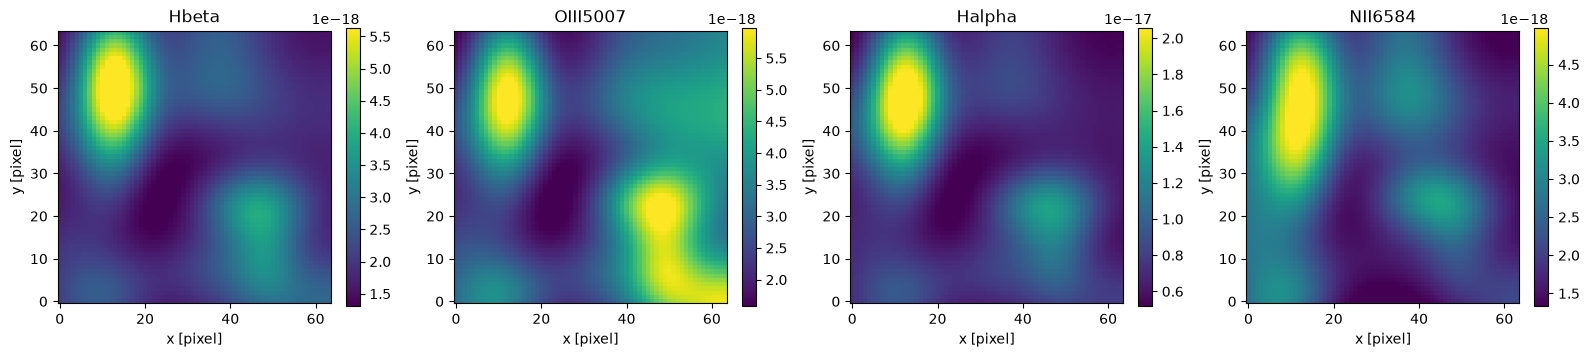

In [9]:
# Plot the synthetic background
#fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig, axes = plt.subplots(1, 4, figsize=(16, 8))
axes = axes.ravel()

for channel, line_name in enumerate(USED_LINES):
    image = fixed_background[channel]

    vmin = np.percentile(image, 2)
    vmax = np.percentile(image, 98)

    im = axes[channel].imshow(
        image,
        origin="lower",
        vmin=vmin,
        vmax=vmax,
    )

    axes[channel].set_title(line_name)
    axes[channel].set_xlabel("x [pixel]")
    axes[channel].set_ylabel("y [pixel]")

    plt.colorbar(
        im,
        ax=axes[channel],
        fraction=0.046,
    )

for axis in axes[len(USED_LINES):]:
    axis.axis("off")

plt.tight_layout()
plt.show()


In [10]:
def create_training_sample(
    pn_models,
    rng,
    fixed_background=None,
):
    if REGENERATE_BACKGROUND_PER_SAMPLE:
        background_maps = make_synthetic_background(
            patch_size=PATCH_SIZE,
            used_lines=USED_LINES,
            rng=rng,
        )
    else:
        if fixed_background is None:
            raise ValueError(
                "fixed_background must be provided when "
                "REGENERATE_BACKGROUND_PER_SAMPLE is False."
            )
        background_maps = fixed_background.copy()

    pn_only_maps = np.zeros_like(background_maps, dtype=np.float32)

    n_sources = int(rng.choice(numbers, p=probabilities))
    positions = choose_source_positions(
        n_sources=n_sources,
        patch_size=PATCH_SIZE,
        margin_pix=SOURCE_MARGIN_PIX,
        minimum_separation_pix=MINIMUM_SOURCE_SEPARATION_PIX,
        rng=rng,
    )

    # One shared PSF width for every PN in this patch.
    psf_fwhm_arcsec = None
    psf_fwhm_pix = None

    if n_sources > 0:
        psf_fwhm_arcsec = sample_truncated_normal(
            rng=rng,
            mean=PSF_FWHM_MEAN_ARCSEC,
            standard_deviation=PSF_FWHM_STD_ARCSEC,
            limits=PSF_FWHM_LIMITS_ARCSEC,
        )
        psf_fwhm_pix = psf_fwhm_arcsec / PIXEL_SCALE_ARCSEC

    sources = []

    for x0, y0 in positions:
        # Select one complete PN spectrum.
        model_index = int(rng.integers(0, len(pn_models)))
        model_row = pn_models.iloc[model_index]

        # Select absolute [O III] 5007 brightness.
        m5007 = float(rng.uniform(*M5007_RANGE))

        ebv = sample_ngc253_ebv(
            rng=rng,
            mode=EBV_MODE,
        )

        line_fluxes = scale_model_from_m5007(
            model_row=model_row,
            m5007=m5007,
            ebv=ebv,
            rv=EXTINCTION_RV,
        )

        psf = normalized_moffat_psf(
            ny=PATCH_SIZE,
            nx=PATCH_SIZE,
            x0=x0,
            y0=y0,
            fwhm_pix=psf_fwhm_pix,
            beta=MOFFAT_BETA,
        )

        # Inject the same source position and PSF into every line map.
        for channel, line_name in enumerate(USED_LINES):
            source_map = (line_fluxes[line_name] * psf).astype(np.float32)
            pn_only_maps[channel] += source_map

        sources.append(
            {
                "x": float(x0),
                "y": float(y0),
                "model_id": str(model_row["model_id"]),
                "m5007": float(m5007),
                "ebv": float(ebv),
                "rv": float(EXTINCTION_RV),
                "psf_fwhm_arcsec": float(psf_fwhm_arcsec),
                "psf_fwhm_pix": float(psf_fwhm_pix),
                "line_fluxes": {
                    line_name: float(flux)
                    for line_name, flux in line_fluxes.items()
                },
            }
        )

    clean_injected_maps = background_maps + pn_only_maps

    # Noise is added after the PN signal has been injected.
    injected_maps = add_noise_to_maps(
        clean_maps=clean_injected_maps,
        rng=rng,
    )

    target = make_centre_heatmap(
        ny=PATCH_SIZE,
        nx=PATCH_SIZE,
        positions=positions,
        sigma_pix=LABEL_SIGMA_PIX,
    )

    return {
        "background_maps": background_maps.astype(np.float32),
        "pn_only_maps": pn_only_maps.astype(np.float32),
        "injected_maps": injected_maps.astype(np.float32),
        "target": target[None, :, :].astype(np.float32),
        "metadata": {
            "n_sources": int(n_sources),
            "psf_fwhm_arcsec": (
                None if psf_fwhm_arcsec is None else float(psf_fwhm_arcsec)
            ),
            "psf_fwhm_pix": (
                None if psf_fwhm_pix is None else float(psf_fwhm_pix)
            ),
            "sources": sources,
        },
    }


In [18]:
sample_rng = np.random.default_rng(90)

example = create_training_sample(
    pn_models=pn_models,
    rng=sample_rng,
    fixed_background=fixed_background,
)

print("Background shape:", example["background_maps"].shape)
print("Injected shape:  ", example["injected_maps"].shape)
print("Target shape:    ", example["target"].shape)

Background shape: (4, 64, 64)
Injected shape:   (4, 64, 64)
Target shape:     (1, 64, 64)

Model=2333419, m5007=24.56, x=28.70, y=21.43, PSF FWHM=0.72 arcsec
  Hbeta     : 5.0829e-17 erg s^-1 cm^-2
  OIII5007  : 4.7851e-16 erg s^-1 cm^-2
  Halpha    : 1.8861e-16 erg s^-1 cm^-2
  NII6584   : 9.1673e-17 erg s^-1 cm^-2

Model=2326382, m5007=26.33, x=15.01, y=48.12, PSF FWHM=0.72 arcsec
  Hbeta     : 8.3769e-18 erg s^-1 cm^-2
  OIII5007  : 9.3923e-17 erg s^-1 cm^-2
  Halpha    : 3.3299e-17 erg s^-1 cm^-2
  NII6584   : 2.0763e-18 erg s^-1 cm^-2

Model=1836309, m5007=24.04, x=51.00, y=18.55, PSF FWHM=0.72 arcsec
  Hbeta     : 6.2375e-17 erg s^-1 cm^-2
  OIII5007  : 7.7229e-16 erg s^-1 cm^-2
  Halpha    : 2.6278e-16 erg s^-1 cm^-2
  NII6584   : 2.5400e-17 erg s^-1 cm^-2


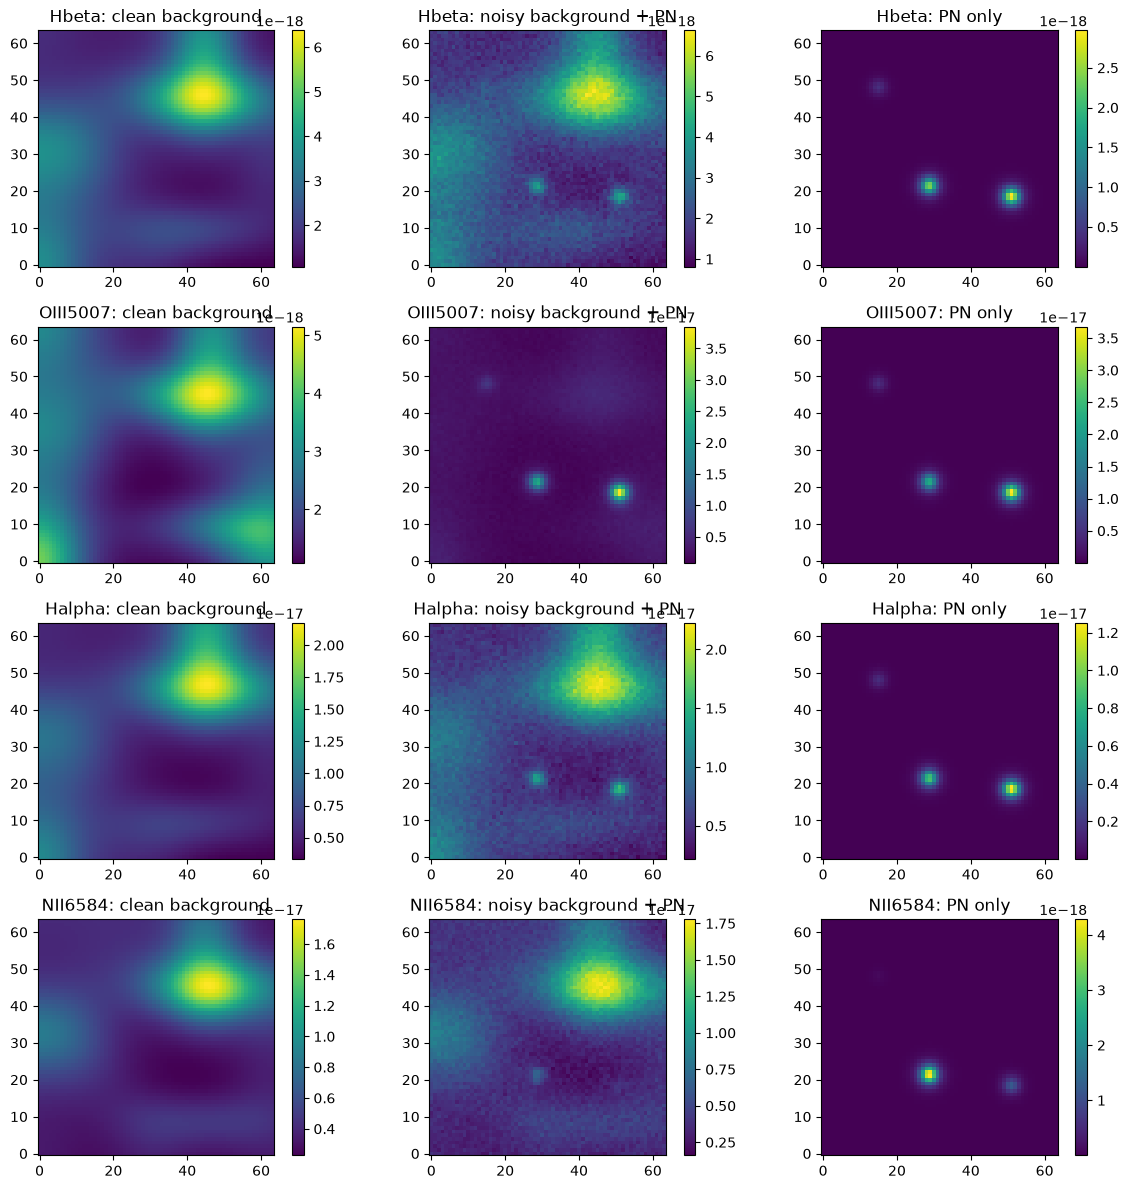

In [22]:
# Compare background, injected map and injected PN only.

fig, axes = plt.subplots(len(USED_LINES), 3, figsize=(12, 3 * len(USED_LINES)))

for channel, line_name in enumerate(USED_LINES):
    background = example["background_maps"][channel]
    injected = example["injected_maps"][channel]
    pn_only = example["pn_only_maps"][channel]

    im0 = axes[channel, 0].imshow(background, origin="lower")
    axes[channel, 0].set_title(f"{line_name}: clean background")
    plt.colorbar(im0, ax=axes[channel, 0], fraction=0.046)

    im1 = axes[channel, 1].imshow(injected, origin="lower")
    axes[channel, 1].set_title(f"{line_name}: noisy background + PN")
    plt.colorbar(im1, ax=axes[channel, 1], fraction=0.046)

    im2 = axes[channel, 2].imshow(pn_only, origin="lower")
    axes[channel, 2].set_title(f"{line_name}: PN only")
    plt.colorbar(im2, ax=axes[channel, 2], fraction=0.046)

plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 5))
plt.imshow(example["target"][0], origin="lower", vmin=0, vmax=1,)
plt.title("PN center target heatmap")
plt.xlabel("x [pixel]")
plt.ylabel("y [pixel]")
plt.colorbar()
plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# 10. Dataset generation
# ============================================================

def create_dataset(
    n_samples,
    pn_models,
    seed,
    fixed_background=None,
    return_oiii_pn_only=False,
):
    rng = np.random.default_rng(seed)

    inputs = np.empty(
        (
            n_samples,
            len(USED_LINES),
            PATCH_SIZE,
            PATCH_SIZE,
        ),
        dtype=np.float32,
    )

    targets = np.empty(
        (
            n_samples,
            1,
            PATCH_SIZE,
            PATCH_SIZE,
        ),
        dtype=np.float32,
    )

    oiii_pn_only = None
    if return_oiii_pn_only:
        oiii_pn_only = np.empty(
            (n_samples, PATCH_SIZE, PATCH_SIZE),
            dtype=np.float32,
        )
        oiii_channel = USED_LINES.index("OIII5007")

    metadata = []

    for sample_index in range(n_samples):
        sample = create_training_sample(
            pn_models=pn_models,
            rng=rng,
            fixed_background=fixed_background,
        )

        inputs[sample_index] = sample["injected_maps"]
        targets[sample_index] = sample["target"]
        metadata.append(sample["metadata"])

        if return_oiii_pn_only:
            oiii_pn_only[sample_index] = sample["pn_only_maps"][oiii_channel]

        if sample_index == 0 or (sample_index + 1) % 100 == 0:
            print(f"Generated {sample_index + 1}/{n_samples}")

    if return_oiii_pn_only:
        return inputs, targets, metadata, oiii_pn_only

    return inputs, targets, metadata


def normalize_inputs_inplace(inputs, channel_means=None, channel_stds=None):
    """Standardize each emission-line channel over samples and spatial pixels.

    For validation or test data, pass the means and standard deviations computed
    from the training data instead of calculating new values.
    """
    if inputs.ndim != 4:
        raise ValueError("inputs must have shape (samples, channels, y, x).")

    n_channels = inputs.shape[1]

    if channel_means is None:
        channel_means = np.array(
            [
                np.mean(inputs[:, channel], dtype=np.float64)
                for channel in range(n_channels)
            ],
            dtype=np.float64,
        )
    else:
        channel_means = np.asarray(channel_means, dtype=np.float64)

    if channel_stds is None:
        channel_stds = np.array(
            [
                np.std(inputs[:, channel], dtype=np.float64)
                for channel in range(n_channels)
            ],
            dtype=np.float64,
        )
    else:
        channel_stds = np.asarray(channel_stds, dtype=np.float64)

    if channel_means.shape != (n_channels,):
        raise ValueError("channel_means must contain one value per channel.")

    if channel_stds.shape != (n_channels,):
        raise ValueError("channel_stds must contain one value per channel.")

    if np.any(~np.isfinite(channel_means)):
        raise ValueError("channel_means contains non-finite values.")

    if np.any(~np.isfinite(channel_stds)) or np.any(channel_stds <= 0):
        raise ValueError("Every channel standard deviation must be finite and positive.")

    for channel in range(n_channels):
        np.subtract(
            inputs[:, channel],
            channel_means[channel],
            out=inputs[:, channel],
        )
        np.divide(
            inputs[:, channel],
            channel_stds[channel],
            out=inputs[:, channel],
        )

    return channel_means, channel_stds


In [15]:
# Start with a small preview dataset.

preview_X, preview_Y, preview_metadata, preview_oiii_pn_only = create_dataset(
    n_samples=10000,
    pn_models=pn_models,
    seed=200,
    fixed_background=fixed_background,
    return_oiii_pn_only=True,
)

# Calculate these statistics from the training set only.
# Reuse the same values later for validation, test, and real observations.
preview_channel_means, preview_channel_stds = normalize_inputs_inplace(preview_X)

print("X shape:", preview_X.shape)
print("Y shape:", preview_Y.shape)
print("X size [MB]:", preview_X.nbytes / 1024**2)

print()
print("Normalization statistics:")
for line_name, mean, std in zip(
    USED_LINES,
    preview_channel_means,
    preview_channel_stds,
):
    print(f"{line_name:10s}: mean={mean:.4e}, std={std:.4e}")


Generated 1/10000
Generated 100/10000
Generated 200/10000
Generated 300/10000
Generated 400/10000
Generated 500/10000
Generated 600/10000
Generated 700/10000
Generated 800/10000
Generated 900/10000
Generated 1000/10000
Generated 1100/10000
Generated 1200/10000
Generated 1300/10000
Generated 1400/10000
Generated 1500/10000
Generated 1600/10000
Generated 1700/10000
Generated 1800/10000
Generated 1900/10000
Generated 2000/10000
Generated 2100/10000
Generated 2200/10000
Generated 2300/10000
Generated 2400/10000
Generated 2500/10000
Generated 2600/10000
Generated 2700/10000
Generated 2800/10000
Generated 2900/10000
Generated 3000/10000
Generated 3100/10000
Generated 3200/10000
Generated 3300/10000
Generated 3400/10000
Generated 3500/10000
Generated 3600/10000
Generated 3700/10000
Generated 3800/10000
Generated 3900/10000
Generated 4000/10000
Generated 4100/10000
Generated 4200/10000
Generated 4300/10000
Generated 4400/10000
Generated 4500/10000
Generated 4600/10000
Generated 4700/10000
Gene

## 11. Normalize and save the dataset


Samples containing PNe: 7517


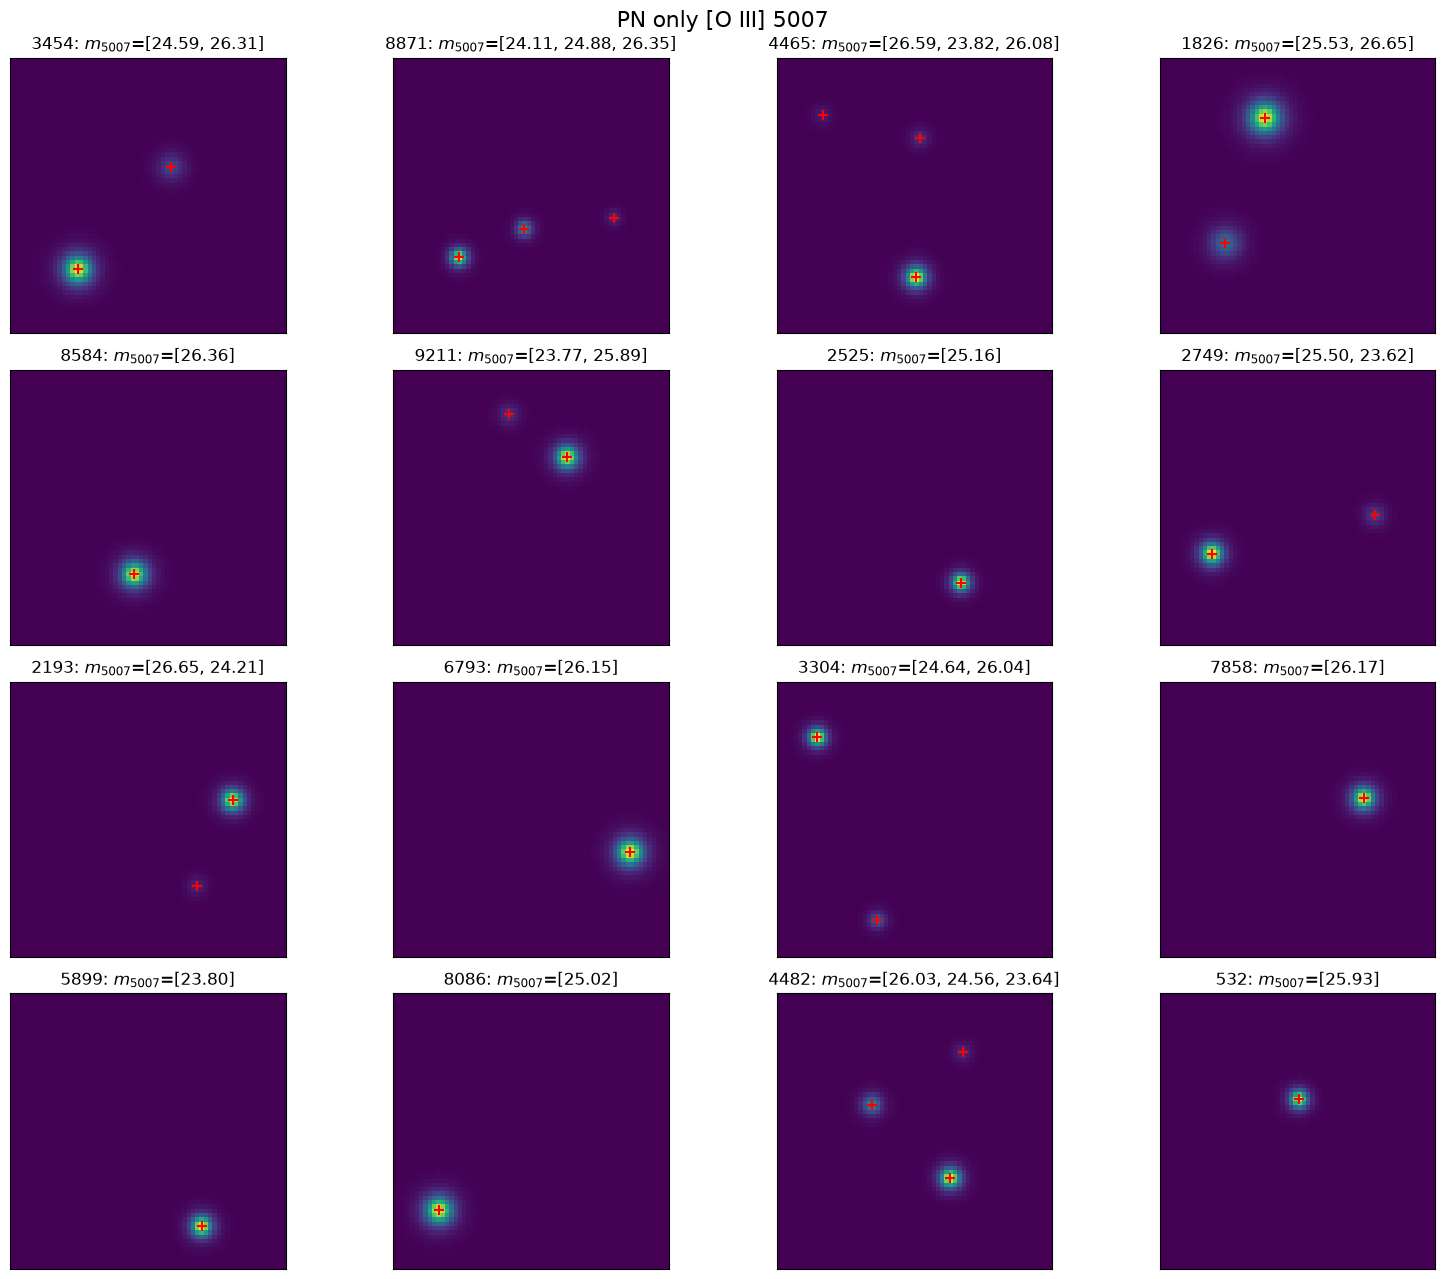

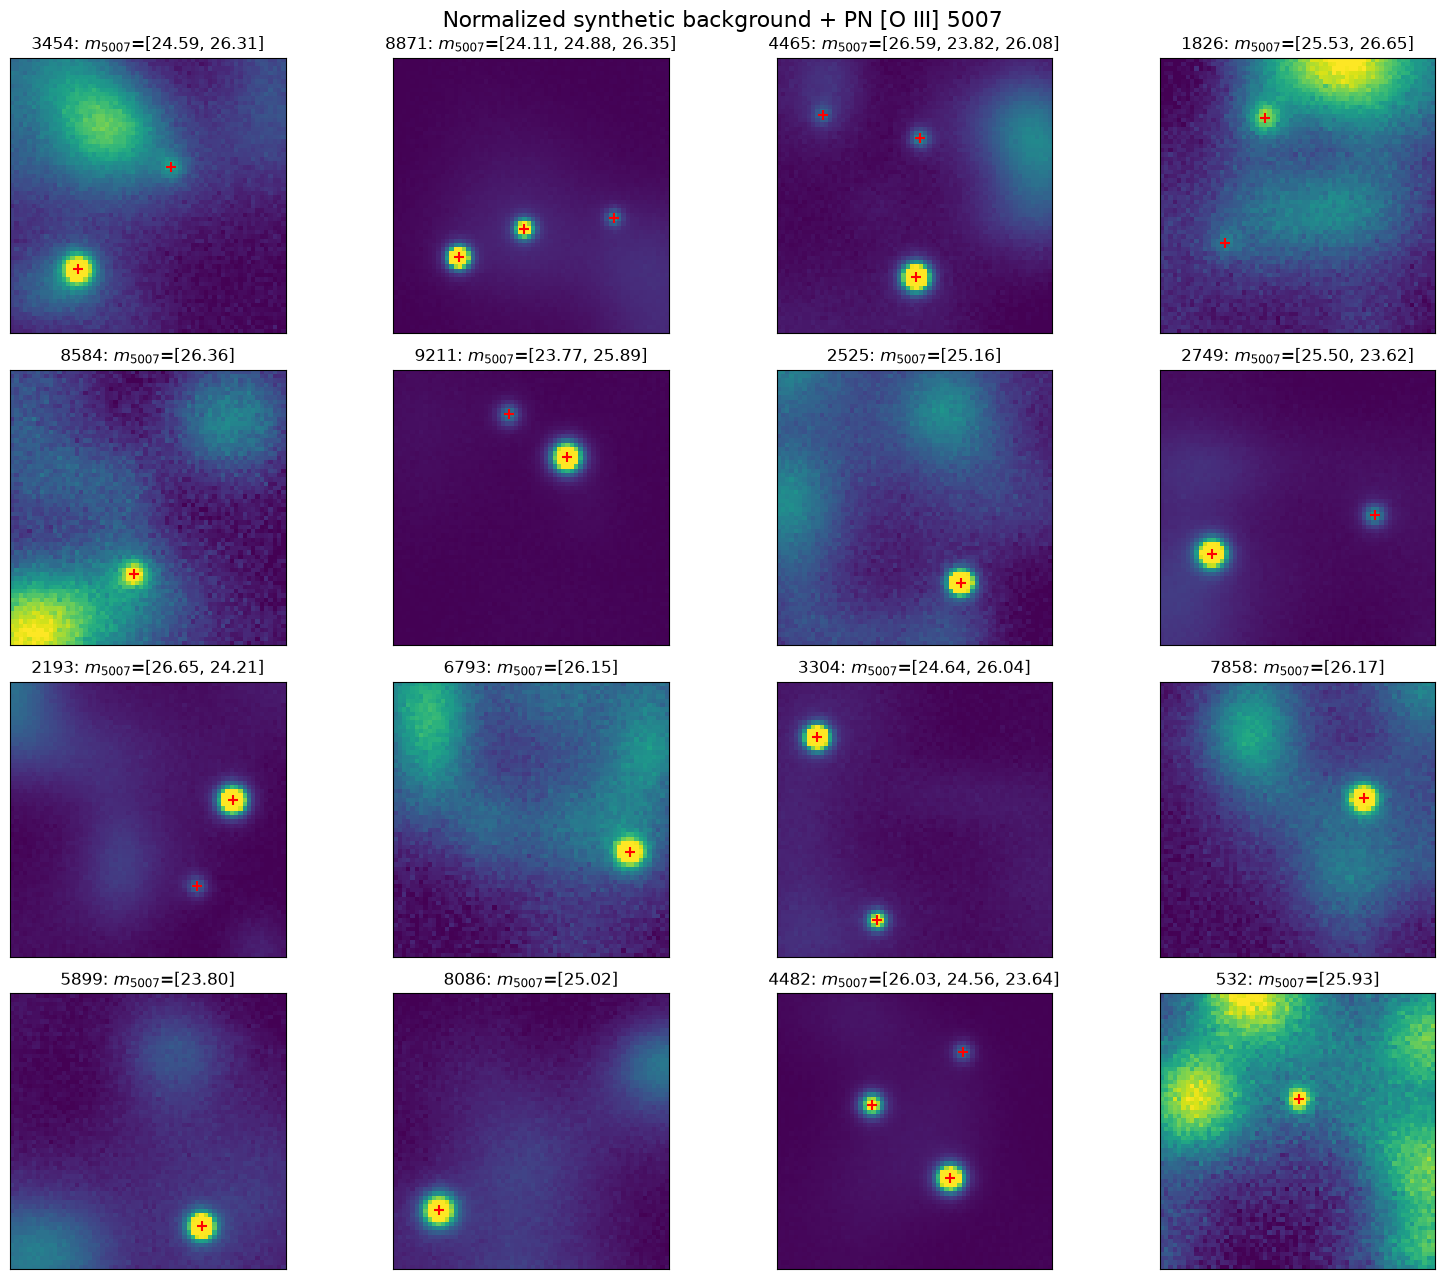

In [29]:
n_show = min(10, len(preview_X))

oiii_channel = USED_LINES.index("OIII5007")

plot_rng = np.random.default_rng(33)
# Indices of samples containing at least one PN
pn_sample_indices = np.array([
    i
    for i, metadata in enumerate(preview_metadata)
    if len(metadata["sources"]) > 0
])

n_show = min(20, len(pn_sample_indices))

plot_rng = np.random.default_rng(123)

sample_indices = plot_rng.choice(
    pn_sample_indices,
    size=n_show,
    replace=False,
)

print(f"Samples containing PNe: {len(pn_sample_indices)}")

fig, axes = plt.subplots(
    4,
    4,
    figsize=(16, 13),
)

axes = axes.ravel()

for axis, sample_index in zip(
    axes,
    sample_indices,
):
    oiii_pn_only = preview_oiii_pn_only[sample_index]
    sources = preview_metadata[sample_index]["sources"]

    im = axis.imshow(
        oiii_pn_only,
        origin="lower",
        vmin=0.0,
        vmax=np.max(oiii_pn_only),
    )

    for source in sources:
        axis.scatter(
            source["x"],
            source["y"],
            marker="+",
            color="r",
            s=50,
            linewidths=1.5,
        )

    magnitudes = ", ".join(f'{source["m5007"]:.2f}' for source in sources)
    axis.set_title(f'{sample_index}: $m_{{5007}}$=[{magnitudes}]')
    axis.set_xticks([])
    axis.set_yticks([])

fig.suptitle("PN only [O III] 5007", fontsize=16)
plt.tight_layout()
plt.savefig('pn1')
plt.show()

# ============================================================
# Plot the same 20 [O III] background + PN maps
# ============================================================

fig, axes = plt.subplots(
    4,
    4,
    figsize=(16, 13),
)

axes = axes.ravel()

for axis, sample_index in zip(
    axes,
    sample_indices,
):
    oiii_with_background = preview_X[
        sample_index,
        oiii_channel,
    ]

    sources = preview_metadata[sample_index]["sources"]

    vmin = np.percentile(
        oiii_with_background,
        1,
    )

    vmax = np.percentile(
        oiii_with_background,
        99.5,
    )

    im = axis.imshow(
        oiii_with_background,
        origin="lower",
        vmin=vmin,
        vmax=vmax,
    )

    for source in sources:
        axis.scatter(
            source["x"],
            source["y"],
            marker="+",
            color="r",
            s=50,
            linewidths=1.5,
        )

    magnitudes = ", ".join(f'{source["m5007"]:.2f}' for source in sources)
    axis.set_title(f'{sample_index}: $m_{{5007}}$=[{magnitudes}]')
    axis.set_xticks([])
    axis.set_yticks([])

fig.suptitle(
    "Normalized synthetic background + PN [O III] 5007",
    fontsize=16,
)

plt.tight_layout()
plt.savefig('pn2')
plt.show()

In [17]:
'''
def save_dataset(
    output_path,
    inputs,
    targets,
    metadata,
    channel_means,
    channel_stds):
    output_path = Path(output_path)

    np.savez_compressed(
        output_path,
        X=inputs,
        Y=targets,
        line_names=np.asarray(USED_LINES),
        channel_means=np.asarray(channel_means, dtype=np.float64),
        channel_stds=np.asarray(channel_stds, dtype=np.float64),
        metadata_json=np.asarray(json.dumps(metadata)))

    print("Saved:", output_path.resolve())


save_dataset(
    output_path="fully_synthetic_PN_10000.npz",
    inputs=preview_X,
    targets=preview_Y,
    metadata=preview_metadata,
    channel_means=preview_channel_means,
    channel_stds=preview_channel_stds)
'''

Saved: /Users/golta/Desktop/Uni/Thesis/PN/fully_synthetic_PN_10000.npz
